In [16]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
CUDA disponible: False


In [17]:
T = 2.0
w_ex = np.sqrt(2) * np.pi

def a_exacta(t):
    return np.cos(w_ex * t) + np.sin(w_ex * t)

def a_exacta_prime(t):
    return w_ex * (-np.sin(w_ex * t) + np.cos(w_ex * t))

def energia_exacta(t):
    a = a_exacta(t); ap = a_exacta_prime(t)
    return ap**2 / 8 + np.pi**2 * a**2 / 4

E0 = np.pi**2 / 2
print(f"w_ex = {w_ex:.4f}")
print(f"a(0) = {a_exacta(0):.4f}, a'(0) = {a_exacta_prime(0):.4f}")
print(f"E(0) = {E0:.4f}")

w_ex = 4.4429
a(0) = 1.0000, a'(0) = 4.4429
E(0) = 4.9348


In [18]:
Nr = 400
t_col = torch.linspace(0, T, Nr).reshape(-1, 1).requires_grad_(True)
t_eval_np = np.linspace(0, T, 1000)

In [19]:
class ModeloA(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.A = torch.nn.Parameter(torch.tensor([1.0, 0.5]))
        self.w = torch.nn.Parameter(torch.tensor([w_ex*0.9, w_ex*1.1]))
        self.b = torch.nn.Parameter(torch.tensor([0.0, 0.0]))

    def a(self, t):
        return (self.A[0]*torch.sin(self.w[0]*t - self.b[0])
              + self.A[1]*torch.sin(self.w[1]*t - self.b[1]))

In [20]:
class ModeloB(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.w1 = torch.nn.Parameter(torch.tensor(1.0))
        self.b1 = torch.nn.Parameter(torch.tensor(0.0))
        self.A  = torch.nn.Parameter(torch.tensor(1.0))
        self.w2 = torch.nn.Parameter(torch.tensor(0.5))
        self.b2 = torch.nn.Parameter(torch.tensor(0.0))

    def a(self, t):
        h1 = torch.sin(self.w1*t + self.b1)
        return self.A*torch.sin(self.w2*h1 + self.b2)

In [21]:
def derivadas_t(model, t):
    a = model.a(t)
    a_t  = torch.autograd.grad(a.sum(),   t, create_graph=True)[0]
    a_tt = torch.autograd.grad(a_t.sum(), t, create_graph=True)[0]
    return a, a_t, a_tt

def perdida_pinn(model, w_ec=1.0, w_ini=10.0):
    a, a_t, a_tt = derivadas_t(model, t_col)
    r = a_tt + 2*np.pi**2 * a
    J_ec = (r**2).mean()

    t0 = torch.tensor([[0.0]], requires_grad=True)
    a0, a0p, _ = derivadas_t(model, t0)
    J_ini = (a0 - 1.0)**2 + (a0p - np.sqrt(2)*np.pi)**2

    return w_ec*J_ec + w_ini*J_ini, J_ec.item(), J_ini.item()

In [22]:
def entrenar(model, iters=5000, lr=1e-2, imprimir_cada=1000, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    historia = {"J": [], "J_ec": [], "J_ini": []}
    for k in range(iters):
        opt.zero_grad()
        J, J_ec, J_ini = perdida_pinn(model)
        J.backward()
        opt.step()
        historia["J"].append(J.item())
        historia["J_ec"].append(J_ec)
        historia["J_ini"].append(J_ini)
        if verbose and (k % imprimir_cada == 0 or k == iters-1):
            print(f"iter {k:5d} | J={J.item():.3e} | J_ec={J_ec:.3e} | J_ini={J_ini:.3e}")
    return model, historia

In [23]:
modelA, histA = entrenar(ModeloA(), iters=5000, lr=1e-2)
modelB, histB = entrenar(ModeloB(), iters=5000, lr=1e-2)

iter     0 | J=5.455e+01 | J_ec=4.581e+00 | J_ini=4.997e+00
iter  1000 | J=4.144e-05 | J_ec=4.143e-05 | J_ini=6.029e-10
iter  2000 | J=4.875e-06 | J_ec=4.875e-06 | J_ini=3.638e-12
iter  3000 | J=1.951e-06 | J_ec=1.951e-06 | J_ini=2.274e-13
iter  4000 | J=1.083e-06 | J_ec=1.083e-06 | J_ini=1.819e-12
iter  4999 | J=5.963e-07 | J_ec=5.963e-07 | J_ini=5.826e-13
iter     0 | J=2.143e+02 | J_ec=4.883e+01 | J_ini=1.655e+01
iter  1000 | J=1.208e+02 | J_ec=3.830e+01 | J_ini=8.248e+00
iter  2000 | J=1.193e+02 | J_ec=3.892e+01 | J_ini=8.042e+00
iter  3000 | J=1.189e+02 | J_ec=3.910e+01 | J_ini=7.978e+00
iter  4000 | J=1.186e+02 | J_ec=3.919e+01 | J_ini=7.944e+00
iter  4999 | J=1.185e+02 | J_ec=3.931e+01 | J_ini=7.915e+00


Modelo A — RMSE = 9.013e-05, max|error| = 1.634e-04
Modelo B — RMSE = 1.208e+00, max|error| = 1.897e+00


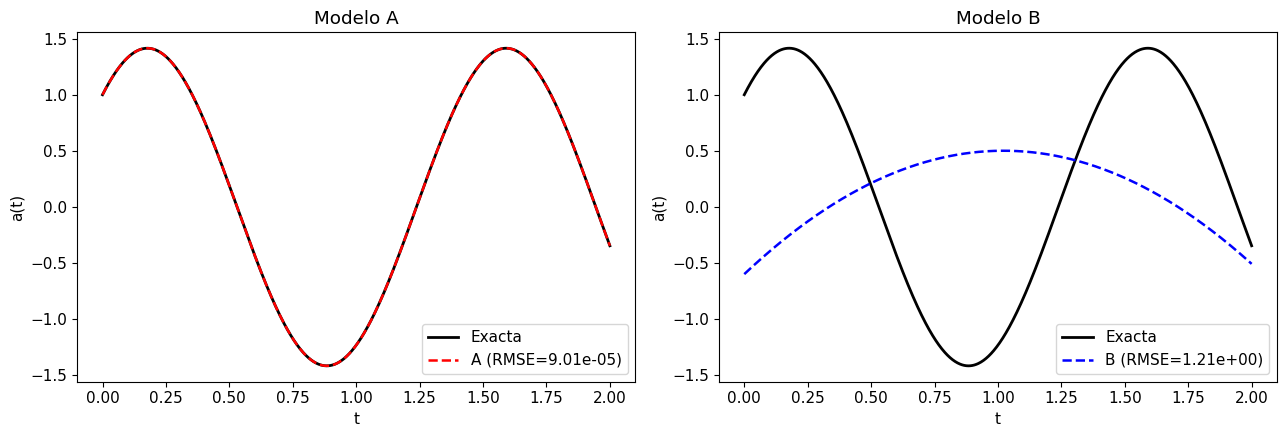

In [24]:
with torch.no_grad():
    t_t = torch.tensor(t_eval_np, dtype=torch.float32).reshape(-1, 1)
    aA = modelA.a(t_t).numpy().ravel()
    aB = modelB.a(t_t).numpy().ravel()

a_ex = a_exacta(t_eval_np)

rmseA = np.sqrt(np.mean((aA - a_ex)**2))
rmseB = np.sqrt(np.mean((aB - a_ex)**2))
maxA  = np.max(np.abs(aA - a_ex))
maxB  = np.max(np.abs(aB - a_ex))

print(f"Modelo A — RMSE = {rmseA:.3e}, max|error| = {maxA:.3e}")
print(f"Modelo B — RMSE = {rmseB:.3e}, max|error| = {maxB:.3e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(t_eval_np, a_ex, 'k-', lw=2, label='Exacta')
ax[0].plot(t_eval_np, aA, 'r--', lw=1.8, label=f'A (RMSE={rmseA:.2e})')
ax[0].set_title('Modelo A'); ax[0].set_xlabel('t'); ax[0].set_ylabel('a(t)'); ax[0].legend()
ax[1].plot(t_eval_np, a_ex, 'k-', lw=2, label='Exacta')
ax[1].plot(t_eval_np, aB, 'b--', lw=1.8, label=f'B (RMSE={rmseB:.2e})')
ax[1].set_title('Modelo B'); ax[1].set_xlabel('t'); ax[1].set_ylabel('a(t)'); ax[1].legend()
plt.tight_layout(); plt.show()

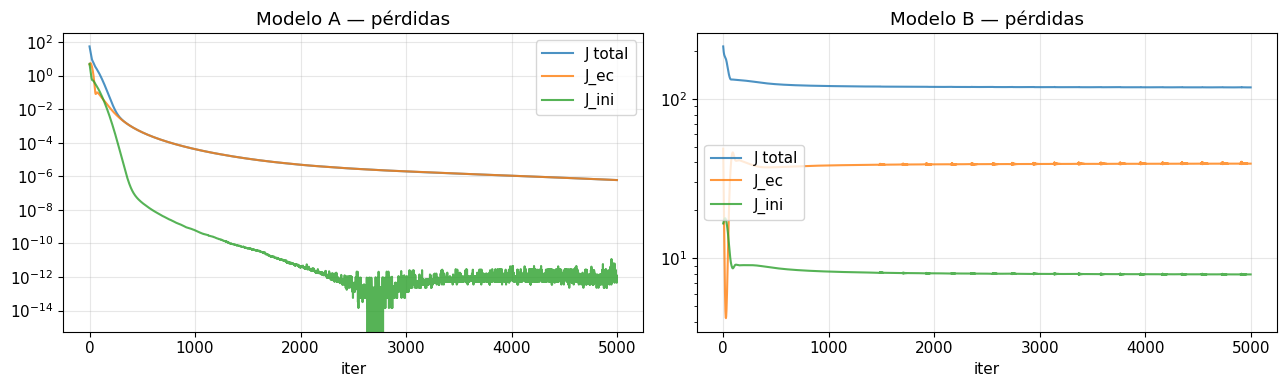

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].semilogy(histA["J"],    label='J total', alpha=0.8)
ax[0].semilogy(histA["J_ec"], label='J_ec',    alpha=0.8)
ax[0].semilogy(histA["J_ini"],label='J_ini',   alpha=0.8)
ax[0].set_title('Modelo A — pérdidas'); ax[0].set_xlabel('iter'); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].semilogy(histB["J"],    label='J total', alpha=0.8)
ax[1].semilogy(histB["J_ec"], label='J_ec',    alpha=0.8)
ax[1].semilogy(histB["J_ini"],label='J_ini',   alpha=0.8)
ax[1].set_title('Modelo B — pérdidas'); ax[1].set_xlabel('iter'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Error relativo máx de energía — Modelo A: 2.321e-04
Error relativo máx de energía — Modelo B: 9.522e-01


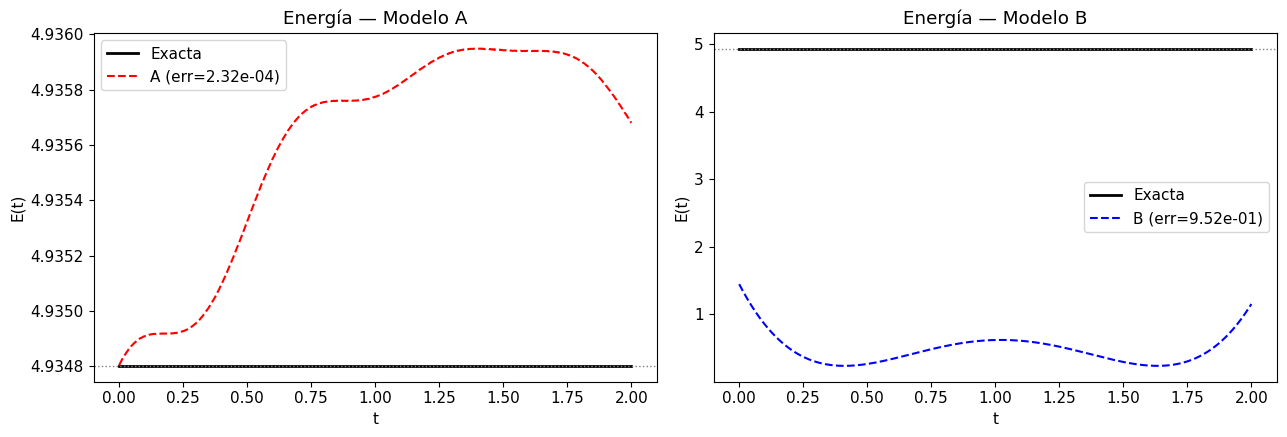

In [26]:
def energia_modelo(model, t_np):
    t = torch.tensor(t_np, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)
    a, a_t, _ = derivadas_t(model, t)
    E = a_t**2/8 + np.pi**2 * a**2/4
    return E.detach().numpy().ravel()

EA = energia_modelo(modelA, t_eval_np)
EB = energia_modelo(modelB, t_eval_np)
E_ex = energia_exacta(t_eval_np)

errE_A = np.max(np.abs(EA - E0)) / E0
errE_B = np.max(np.abs(EB - E0)) / E0
print(f"Error relativo máx de energía — Modelo A: {errE_A:.3e}")
print(f"Error relativo máx de energía — Modelo B: {errE_B:.3e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(t_eval_np, E_ex, 'k-', lw=2, label='Exacta')
ax[0].plot(t_eval_np, EA, 'r--', label=f'A (err={errE_A:.2e})')
ax[0].axhline(E0, color='gray', ls=':', lw=1)
ax[0].set_title('Energía — Modelo A'); ax[0].set_xlabel('t'); ax[0].set_ylabel('E(t)'); ax[0].legend()

ax[1].plot(t_eval_np, E_ex, 'k-', lw=2, label='Exacta')
ax[1].plot(t_eval_np, EB, 'b--', label=f'B (err={errE_B:.2e})')
ax[1].axhline(E0, color='gray', ls=':', lw=1)
ax[1].set_title('Energía — Modelo B'); ax[1].set_xlabel('t'); ax[1].set_ylabel('E(t)'); ax[1].legend()
plt.tight_layout(); plt.show()

max|dE/dt| Modelo A: 2.427e-03
max|dE/dt| Modelo B: 7.317e+00


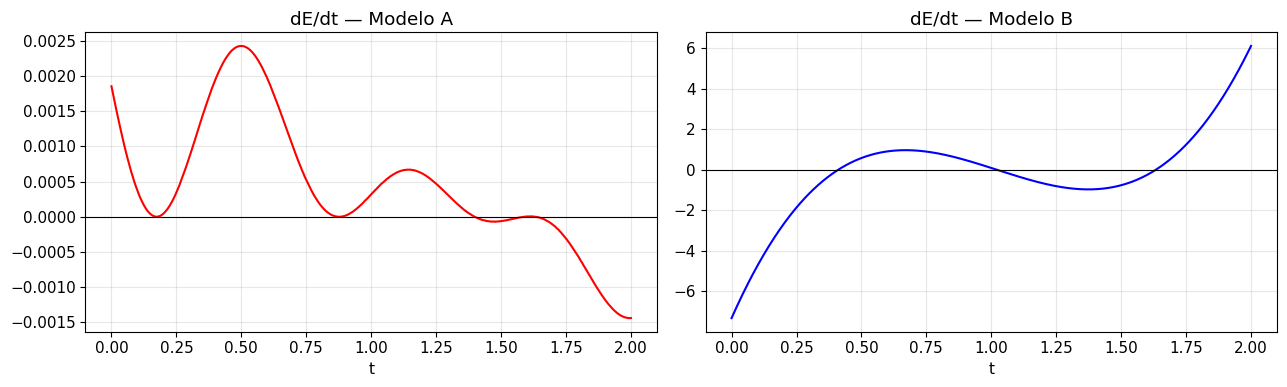

In [27]:
def dE_dt(model, t_np):
    t = torch.tensor(t_np, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)
    a, a_t, a_tt = derivadas_t(model, t)
    r = a_tt + 2*np.pi**2 * a
    return (a_t * r / 4).detach().numpy().ravel()

dEA = dE_dt(modelA, t_eval_np)
dEB = dE_dt(modelB, t_eval_np)

print(f"max|dE/dt| Modelo A: {np.max(np.abs(dEA)):.3e}")
print(f"max|dE/dt| Modelo B: {np.max(np.abs(dEB)):.3e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t_eval_np, dEA, 'r'); ax[0].axhline(0, color='k', lw=0.8)
ax[0].set_title('dE/dt — Modelo A'); ax[0].set_xlabel('t'); ax[0].grid(alpha=0.3)
ax[1].plot(t_eval_np, dEB, 'b'); ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('dE/dt — Modelo B'); ax[1].set_xlabel('t'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [28]:
tabla = pd.DataFrame({
    "Métrica": ["RMSE a(t)", "max|error| a(t)", "Error rel. energía máx", "max|dE/dt|"],
    "Modelo A": [f"{rmseA:.2e}", f"{maxA:.2e}", f"{errE_A:.2e}", f"{np.max(np.abs(dEA)):.2e}"],
    "Modelo B": [f"{rmseB:.2e}", f"{maxB:.2e}", f"{errE_B:.2e}", f"{np.max(np.abs(dEB)):.2e}"],
})
print(tabla.to_string(index=False))

               Métrica Modelo A Modelo B
             RMSE a(t) 9.01e-05 1.21e+00
       max|error| a(t) 1.63e-04 1.90e+00
Error rel. energía máx 2.32e-04 9.52e-01
            max|dE/dt| 2.43e-03 7.32e+00


In [29]:
resultados_A = []
for semilla in range(5):
    torch.manual_seed(semilla)
    m, _ = entrenar(ModeloA(), iters=3000, lr=1e-2, verbose=False)
    with torch.no_grad():
        t_t = torch.tensor(t_eval_np, dtype=torch.float32).reshape(-1, 1)
        aA_s = m.a(t_t).numpy().ravel()
    rmse = np.sqrt(np.mean((aA_s - a_ex)**2))
    resultados_A.append(rmse)
    print(f"semilla {semilla}: RMSE = {rmse:.3e}")

print("\nRMSE Modelo A en 5 semillas:", resultados_A)
print(f"media ± std: {np.mean(resultados_A):.3e} ± {np.std(resultados_A):.3e}")

semilla 0: RMSE = 1.241e-04
semilla 1: RMSE = 1.241e-04
semilla 2: RMSE = 1.241e-04
semilla 3: RMSE = 1.241e-04
semilla 4: RMSE = 1.241e-04

RMSE Modelo A en 5 semillas: [np.float64(0.00012406683125752455), np.float64(0.00012406683125752455), np.float64(0.00012406683125752455), np.float64(0.00012406683125752455), np.float64(0.00012406683125752455)]
media ± std: 1.241e-04 ± 0.000e+00


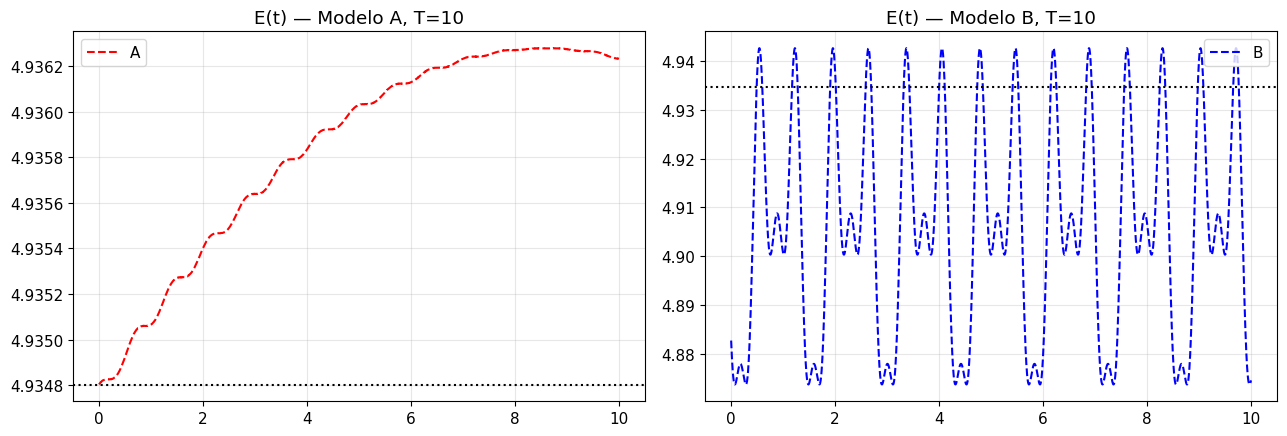

In [30]:
T = 10.0
t_col = torch.linspace(0, T, 1000).reshape(-1, 1).requires_grad_(True)
t_eval_np = np.linspace(0, T, 2000)

modelA_long, _ = entrenar(ModeloA(), iters=8000, lr=5e-3, verbose=False)
modelB_long, _ = entrenar(ModeloB(), iters=8000, lr=5e-3, verbose=False)

EA_long = energia_modelo(modelA_long, t_eval_np)
EB_long = energia_modelo(modelB_long, t_eval_np)
E0_long = np.pi**2 / 2

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(t_eval_np, EA_long, 'r--', label='A')
ax[0].axhline(E0_long, color='k', ls=':')
ax[0].set_title('E(t) — Modelo A, T=10')
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(t_eval_np, EB_long, 'b--', label='B')
ax[1].axhline(E0_long, color='k', ls=':')
ax[1].set_title('E(t) — Modelo B, T=10')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()